## In this code

We load the dataset and inspect the dataset.

In [2]:
import pandas as pd

df = pd.read_csv("data/oc_risk50k_single_dataset.csv")

print("Dataset dimensions:")
print(df.shape)

print("\nFirst five rows:")
print(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset dimensions:
(50000, 52)

First five rows:
  Patient_ID   Age  Menopausal_Status  Age_At_Menarche  Age_At_Menopause  \
0  PAT_00001  53.8                  1             11.0              48.6   
1  PAT_00002  66.8                  1             13.2              50.4   
2  PAT_00003  51.9                  1             13.2              50.9   
3  PAT_00004  67.6                  1             12.3              51.1   
4  PAT_00005  80.5                  1             14.9              52.1   

   Family_History  BRCA1_Status  BRCA2_Status  Lynch_Syndrome_Status   BMI  \
0               0             0             0                      0  34.5   
1               1             0             0                      0  18.5   
2               1             0             0                      0  23.2   
3               0             0             0                      0  24.7   
4               1             0             0                      0  22.0   

   ...  Charlson_Comorbi

## In this code

We inspect column types and check for missing values

- Data types: Are the columns integers, floating-point numbers, or strings? This helps us understand how the data is represented.
- Missing values: Are some measurements unavailable for certain patients?
- Duplicates: Do we have repeated records that might affect our experiments?

In [4]:
print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:")
print(df.duplicated().sum())


Column information:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 52 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Patient_ID                         50000 non-null  str    
 1   Age                                50000 non-null  float64
 2   Menopausal_Status                  50000 non-null  int64  
 3   Age_At_Menarche                    50000 non-null  float64
 4   Age_At_Menopause                   50000 non-null  float64
 5   Family_History                     50000 non-null  int64  
 6   BRCA1_Status                       50000 non-null  int64  
 7   BRCA2_Status                       50000 non-null  int64  
 8   Lynch_Syndrome_Status              50000 non-null  int64  
 9   BMI                                50000 non-null  float64
 10  Parity                             50000 non-null  int64  
 11  Oral_Contraceptive_History         50000 non

Excellent! This is a very clean dataset from a data-quality perspective. We have 50,000 records, no duplicate rows, and only four columns with missing values.

Let's not clean anything yet. I want to point out three things.

### **1. Your dataset has very few missing values**

Only these four columns have missing data:

| Column             | Missing | Percentage |
| ------------------ | ------- | ---------- |
| HE4                | 2,108   | 4.22%      |
| CA125              | 2,036   | 4.07%      |
| Imaging_Risk_Score | 1,959   | 3.92%      |
| Albumin            | 1,922   | 3.84%      |

This is good. We can decide how to handle them when we decide which features to use.

### **2. Your columns have different data types**

You have:

- `float64`: continuous numerical measurements, such as Age and BMI.
- `int64`: integer-valued features, many of which are probably categorical or binary.
- `str`: identifiers and partition labels.

One important distinction: an integer column isn't necessarily a continuous numerical variable. For example, `BRCA1_Status` might be encoded as 0 and 1, representing categories.

We'll investigate those encodings later.

### **3. No duplicate rows!**

That's good. We don't need to worry about exact duplicate records at this stage.

## **Step 6. Let's investigate the prediction target**

Now I want to answer a very basic question:

**How many patients in this dataset have ovarian cancer, and how many don't?**

Add this to `exploration.py`:

In [5]:
print("\nCancer status distribution:")
print(df["Ovarian_Cancer_Status"].value_counts())

print("\nCancer status percentages:")
print(df["Ovarian_Cancer_Status"].value_counts(normalize=True) * 100)


Cancer status distribution:
Ovarian_Cancer_Status
0    25000
1    25000
Name: count, dtype: int64

Cancer status percentages:
Ovarian_Cancer_Status
0    50.0
1    50.0
Name: proportion, dtype: float64


Perfect. We have a **50/50 class distribution**:

| Cancer status | Patients   | Percentage |
| ------------- | ---------- | ---------- |
| No cancer (0) | 25,000     | 50%        |
| Cancer (1)    | 25,000     | 50%        |
| **Total**     | **50,000** | **100%**   |

This is a useful property of the synthetic dataset. It means we don't have to deal with severe class imbalance in our initial experiments.

One important caveat for the eventual report: this is an artificially balanced dataset, so its class distribution does not represent real-world ovarian cancer prevalence.

## **Step 7. Check the existing data partitions**

Before training anything, let's verify that the Train, Validation, and Test sets each have a reasonable distribution of cancer and non-cancer cases.

Add this to `exploration.py`:

In [6]:
print("\nCancer distribution by partition:")
print(pd.crosstab(df["Partition"], df["Ovarian_Cancer_Status"], margins=True))

print("\nCancer percentages by partition:")
print(pd.crosstab(df["Partition"],
      df["Ovarian_Cancer_Status"], normalize="index") * 100)



Cancer distribution by partition:
Ovarian_Cancer_Status      0      1    All
Partition                                 
Test                    3719   3812   7531
Train                  17513  17433  34946
Validation              3768   3755   7523
All                    25000  25000  50000

Cancer percentages by partition:
Ovarian_Cancer_Status          0          1
Partition                                  
Test                   49.382552  50.617448
Train                  50.114462  49.885538
Validation             50.086402  49.913598


Beautiful. This is exactly what we wanted to see!

Your three partitions are all reasonably balanced:

| Partition  | Non-cancer | Cancer |
| ---------- | ---------- | ------ |
| Train      | 50.11%     | 49.89% |
| Validation | 50.09%     | 49.91% |
| Test       | 49.38%     | 50.62% |

The test set is slightly different, but nothing concerning.

**Decision: Keep the existing partitions. Don't reshuffle the dataset.**

We're now finished with our initial dataset-level checks:

- &#x20;Dataset loads successfully.
- &#x20;50,000 records and 52 columns.
- &#x20;No duplicate rows.
- &#x20;Missing values identified.
- &#x20;Target distribution inspected.
- &#x20;Existing partitions verified.

## **Step 8. Let's finally look at our features!**

Now I want to understand what values our proposed 12 features actually take.

Add this:

In [8]:
features = [
    "Age",
    "Menopausal_Status",
    "Family_History",
    "BRCA1_Status",
    "BRCA2_Status",
    "Lynch_Syndrome_Status",
    "BMI",
    "Parity",
    "Oral_Contraceptive_History",
    "Endometriosis_History",
    "Hormone_Therapy_History",
    "Tubal_Ligation_History"
]

print("\nFeature summary:")
print(df[features].describe().T)


Feature summary:
                              count      mean        std   min   25%   50%  \
Age                         50000.0  57.98009  12.087616  18.0  50.0  58.2   
Menopausal_Status           50000.0   0.75114   0.432357   0.0   1.0   1.0   
Family_History              50000.0   0.18080   0.384856   0.0   0.0   0.0   
BRCA1_Status                50000.0   0.09406   0.291915   0.0   0.0   0.0   
BRCA2_Status                50000.0   0.07608   0.265129   0.0   0.0   0.0   
Lynch_Syndrome_Status       50000.0   0.02696   0.161968   0.0   0.0   0.0   
BMI                         50000.0  26.29990   5.295263  16.0  22.5  25.8   
Parity                      50000.0   1.79928   1.332977   0.0   1.0   2.0   
Oral_Contraceptive_History  50000.0   0.40834   0.491532   0.0   0.0   0.0   
Endometriosis_History       50000.0   0.11998   0.324941   0.0   0.0   0.0   
Hormone_Therapy_History     50000.0   0.11218   0.315591   0.0   0.0   0.0   
Tubal_Ligation_History      50000.0   0.14736 

Excellent! This is exactly the information we needed. Your 12 candidate features look manageable, and we can already distinguish between two types of variables.

## **1. Understanding your features**

**Continuous numerical features (4):**

| Feature | Mean  | Minimum | Maximum |
| ------- | ----- | ------- | ------- |
| Age     | 57.98 | 18      | 90      |
| BMI     | 26.30 | 16      | 50      |
| Parity  | 1.80  | 0       | 8       |

Technically, Parity is a discrete count, but we'll treat it as an ordered numerical feature initially.

**Binary categorical features (9):**

- Menopausal_Status
- Family_History
- BRCA1_Status
- BRCA2_Status
- Lynch_Syndrome_Status
- Oral_Contraceptive_History
- Endometriosis_History
- Hormone_Therapy_History
- Tubal_Ligation_History

These appear to use 0/1 encoding.

For Bayesian Networks, we'll eventually represent these as categorical states rather than treating them as continuous measurements.

## **2. One interesting observation**

Look at the genetic variables:

| Feature        | Percentage positive |
| -------------- | ------------------- |
| BRCA1          | 9.41%               |
| BRCA2          | 7.61%               |
| Lynch Syndrome | 2.70%               |

These are relatively uncommon states.

This matters because when we construct CPTs, some combinations of genetic variables may have relatively few observations. Remember your professor's recommendation about probability smoothing? This is one reason we'll need it.

## **3. Our next task: inspect categorical values**

Before deciding how to discretize anything, let's verify the actual values of our categorical variables.

Add this to `exploration.py`:

In [9]:
categorical_features = [
    "Menopausal_Status",
    "Family_History",
    "BRCA1_Status",
    "BRCA2_Status",
    "Lynch_Syndrome_Status",
    "Oral_Contraceptive_History",
    "Endometriosis_History",
    "Hormone_Therapy_History",
    "Tubal_Ligation_History"
]

for col in categorical_features:
    print(f"\n{col}:")
    print(df[col].value_counts().sort_index())


Menopausal_Status:
Menopausal_Status
0    12443
1    37557
Name: count, dtype: int64

Family_History:
Family_History
0    40960
1     9040
Name: count, dtype: int64

BRCA1_Status:
BRCA1_Status
0    45297
1     4703
Name: count, dtype: int64

BRCA2_Status:
BRCA2_Status
0    46196
1     3804
Name: count, dtype: int64

Lynch_Syndrome_Status:
Lynch_Syndrome_Status
0    48652
1     1348
Name: count, dtype: int64

Oral_Contraceptive_History:
Oral_Contraceptive_History
0    29583
1    20417
Name: count, dtype: int64

Endometriosis_History:
Endometriosis_History
0    44001
1     5999
Name: count, dtype: int64

Hormone_Therapy_History:
Hormone_Therapy_History
0    44391
1     5609
Name: count, dtype: int64

Tubal_Ligation_History:
Tubal_Ligation_History
0    42632
1     7368
Name: count, dtype: int64


Great! All nine categorical features contain exactly two values: `0` and `1`. No unexpected categories. That's what we hoped to see.

A quick observation:

- `BRCA1_Status`, `BRCA2_Status`, and `Lynch_Syndrome_Status` are relatively sparse.
- `Menopausal_Status` is somewhat imbalanced (75% vs. 25%).
- The other variables have reasonable variation.

We can tentatively treat all nine as binary categorical variables.

## **Step 9. Let's examine how features relate to cancer status**

Now we're going to do our first genuinely interesting piece of data analysis.

So far, we've examined each feature independently. But we haven't asked whether these features differ between cancer and non-cancer patients.

For example:

- Are patients with a BRCA1 mutation more likely to have cancer in this dataset?
- Does cancer prevalence increase with age?
- Is family history associated with cancer status?

Let's investigate that.

Add this code:

In [10]:
for col in categorical_features:
    print(f"\n{col}:")
    result = pd.crosstab(
        df[col], df["Ovarian_Cancer_Status"], normalize="index") * 100
    print(result.round(2))


Menopausal_Status:
Ovarian_Cancer_Status      0      1
Menopausal_Status                  
0                      71.05  28.95
1                      43.03  56.97

Family_History:
Ovarian_Cancer_Status      0      1
Family_History                     
0                      56.28  43.72
1                      21.56  78.44

BRCA1_Status:
Ovarian_Cancer_Status      0      1
BRCA1_Status                       
0                      54.54  45.46
1                       6.25  93.75

BRCA2_Status:
Ovarian_Cancer_Status      0      1
BRCA2_Status                       
0                      53.51  46.49
1                       7.39  92.61

Lynch_Syndrome_Status:
Ovarian_Cancer_Status      0      1
Lynch_Syndrome_Status              
0                      51.16  48.84
1                       8.16  91.84

Oral_Contraceptive_History:
Ovarian_Cancer_Status           0      1
Oral_Contraceptive_History              
0                           40.86  59.14
1                           63.24  36

Now we're getting somewhere! This is our first meaningful look at the relationships in OC-Risk50K.

There are some very strong associations in this dataset, particularly for genetic variables.

Let's interpret the results.

## **1. What we've discovered**

Your results show the following cancer rates within each category:

| Feature                    | Category 0 | Category 1 |
| -------------------------- | ---------- | ---------- |
| Menopausal status          | 28.95%     | 56.97%     |
| Family history             | 43.72%     | 78.44%     |
| BRCA1                      | 45.46%     | 93.75%     |
| BRCA2                      | 46.49%     | 92.61%     |
| Lynch syndrome             | 48.84%     | 91.84%     |
| Oral contraceptive history | 59.14%     | 36.76%     |
| Endometriosis              | 46.61%     | 74.86%     |
| Hormone therapy            | 49.07%     | 57.39%     |
| Tubal ligation             | 54.10%     | 26.30%     |

A few observations:

- **BRCA1, BRCA2, and Lynch syndrome:** Extremely strong associations with the target.
- **Family history:** Also a substantial association.
- **Endometriosis:** A notable association.
- **Oral contraceptive history and tubal ligation:** Their category-1 groups have lower cancer rates.
- **Hormone therapy:** A comparatively modest association.

These are patterns in your synthetic dataset, not estimates of real-world medical risk.

## **2. Something interesting about your Bayesian Network**

Remember that your project isn't simply about predicting cancer. It's about comparing two different network structures.

These results give us some initial intuition about which variables might be informative, but they do **not** tell us which variables should be connected directly to the cancer node.

For example, BRCA1 and BRCA2 could be correlated with each other, and family history could be related to both. We shouldn't automatically draw three independent arrows into the target just because their individual associations are strong.

That's precisely where network structure becomes interesting.

## **3. Our next step: investigate numerical features**

We've examined the binary variables. Now let's examine three numerical features:

- Age
- BMI
- Parity

I want to see whether their distributions differ between cancer and non-cancer patients.

Add this to `exploration.py`:

In [11]:
numerical_features = ["Age", "BMI", "Parity"]
print("\nNumerical features by cancer status:")
print(df.groupby("Ovarian_Cancer_Status")[
      numerical_features].describe().round(2))


Numerical features by cancer status:
                           Age                                              \
                         count   mean    std   min   25%   50%   75%   max   
Ovarian_Cancer_Status                                                        
0                      25000.0  54.83  12.72  18.0  46.2  54.7  63.4  90.0   
1                      25000.0  61.13  10.51  20.9  54.0  61.1  68.2  90.0   

                           BMI        ...               Parity              \
                         count  mean  ...   75%   max    count  mean   std   
Ovarian_Cancer_Status                 ...                                    
0                      25000.0  26.3  ...  29.5  50.0  25000.0  1.79  1.34   
1                      25000.0  26.3  ...  29.5  50.0  25000.0  1.80  1.33   

                                                
                       min  25%  50%  75%  max  
Ovarian_Cancer_Status                           
0                      0.0  1.0  

Nice! There's an interesting pattern here, although our output is a little too wide to read comfortably.

Let's focus on what we can establish.

## **1. Age appears particularly informative**

| Statistic  | No cancer | Cancer |
| ---------- | --------- | ------ |
| Mean age   | 54.83     | 61.13  |
| Median age | 54.7      | 61.1   |

The cancer group is approximately **6.3 years older on average**.

That's a noticeable difference in this synthetic dataset.

## **2. Parity doesn't appear very informative**

From the visible output:

| Statistic     | No cancer | Cancer |
| ------------- | --------- | ------ |
| Mean parity   | 1.79      | 1.80   |
| Median parity | 2         | 2      |

The distributions appear very similar. Parity might contribute relatively little predictive information.

## **3. I want to inspect BMI separately**

Your pandas output truncated the middle columns, so we can't actually see the BMI statistics yet.

Let's make the output easier to read.

Add:

In [12]:
print("\nAge, BMI, and Parity by cancer status:")
print(df.groupby("Ovarian_Cancer_Status")[numerical_features].agg(
    ["mean", "median", "std"]).round(2).T)


Age, BMI, and Parity by cancer status:
Ovarian_Cancer_Status      0      1
Age    mean            54.83  61.13
       median          54.70  61.10
       std             12.72  10.51
BMI    mean            26.30  26.30
       median          25.80  25.80
       std              5.29   5.31
Parity mean             1.79   1.80
       median           2.00   2.00
       std              1.34   1.33


Excellent. Now we have a pretty clear picture of our initial 12 features.

Here's what we've learned:

| Feature | No cancer (mean) | Cancer (mean) | Initial observation   |
| ------- | ---------------- | ------------- | --------------------- |
| Age     | 54.83            | 61.13         | Noticeable difference |
| BMI     | 26.30            | 26.30         | Almost identical      |
| Parity  | 1.79             | 1.80          | Almost identical      |

Two things stand out:

- **Age** appears potentially informative.
- **BMI and Parity** have almost identical distributions between the two groups.

Don't remove BMI or Parity just yet. A feature that has little individual association can still contribute information when combined with other variables.

## **Step 10. Let's visualize the distributions**

Before we start preprocessing, I want you to see these differences rather than just read numbers.

Add this to `exploration.py`:

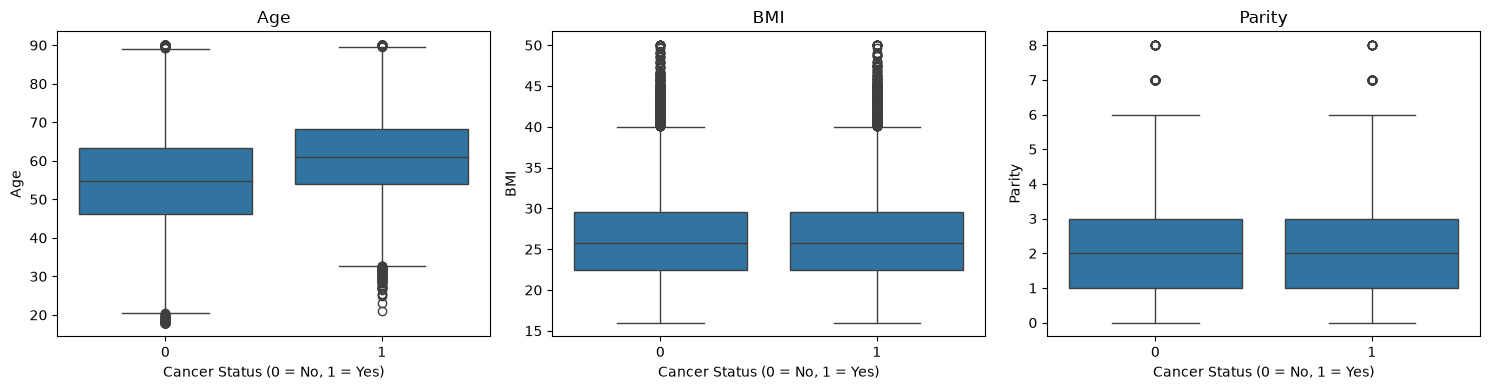

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, numerical_features):
    sns.boxplot(data=df, x="Ovarian_Cancer_Status", y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Cancer Status (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()

These plots look good! And they confirm exactly what we saw in the numerical summaries.

Let's interpret them:

### **Age**

There is a noticeable difference between the two groups.

- Non-cancer patients have a median age of approximately 55.
- Cancer patients have a median age of approximately 61.
- The distributions overlap, but the cancer group is shifted toward older ages.

Age looks like a potentially useful predictor.

### **BMI**

The two distributions are almost indistinguishable.

Both groups have:

- Median BMI around 25.8.
- Similar interquartile ranges.
- Similar overall distributions.

### **Parity**

Essentially identical distributions between the two groups.

Neither the median nor the interquartile range shows a meaningful difference.

**One note:** Don't automatically remove the outliers shown in the plots. They aren't necessarily erroneous observations.

## **Step 11. Let's create our first processed dataset!**

I think we've done enough initial exploration. Let's prepare a smaller dataset containing only our selected features.

Create a folder called `processed` inside `data`:

```
cs-4710-project-final/
├── data/
│   ├── oc_risk50k_single_dataset.csv
│   └── processed/
├── exploration.py
```

Now, add this to the bottom of `exploration.py`:

In [14]:
from pathlib import Path

columns = features + ["Ovarian_Cancer_Status", "Partition"]

df_processed = df[columns].copy()

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

df_processed.to_csv(output_dir / "oc_risk50k_selected.csv", index=False)

print("\nProcessed dataset:")
print(df_processed.shape)

print("\nSaved successfully!")


Processed dataset:
(50000, 14)

Saved successfully!


Fantastic! I checked the CSV you uploaded, and everything looks correct. 🎉

Milestone completed

Your processed dataset has:

| Property         | Result |
| ---------------- | ------ |
| Records          | 50,000 |
| Features         | 12     |
| Target variables | 1      |
| Partition column | 1      |
| Missing values   | 0      |
| Total columns    | 14     |

The original train/validation/test partitions have also been preserved.

## **Step 12. Separate the three datasets**

Now let's do something simple but important: create separate DataFrames for training, validation, and testing.

Please go to `main.ipynb` to continue reading this thread.